# Predicting Heart Disease with Logistic Regression

**Dataset:** Cleveland Heart Disease data (303 patients, 13 clinical features + 1 diagnosis column)

**Goal:** Explore the data and build a logistic regression model that predicts whether a patient has heart disease.

**Steps**
1. Load the data and give the columns meaningful names
2. Clean the data (missing values, target conversion)
3. Exploratory data analysis (EDA)
4. Prepare features (encoding + scaling)
5. Train a logistic regression model
6. Evaluate the model
7. Interpret the coefficients

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the data

The CSV file includes a **header row** with the column names. The last column is called `target`, but it still holds the
original 0–4 diagnosis codes, so we rename it to `num` and create our own yes/no target in Section 3.2.
Missing values are stored as `?`, so we tell pandas to treat `?` as missing (`NaN`).

| Column | Meaning |
|---|---|
| age | Age in years |
| sex | 1 = male, 0 = female |
| cp | Chest pain type (1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| restecg | Resting ECG result (0 = normal, 1 = ST-T abnormality, 2 = left ventricular hypertrophy) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina (1 = yes, 0 = no) |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Slope of peak exercise ST segment (1 = upsloping, 2 = flat, 3 = downsloping) |
| ca | Number of major vessels (0–3) coloured by fluoroscopy |
| thal | Thalassemia test (3 = normal, 6 = fixed defect, 7 = reversible defect) |
| num | Diagnosis: 0 = no disease, 1–4 = increasing severity of disease |

In [2]:
df = pd.read_csv("heart_disease.csv", na_values="?")   # first row of the file is the header
df = df.rename(columns={"target": "num"})               # still the 0-4 diagnosis codes
print("Shape:", df.shape)
print("Diagnosis values in the file:", sorted(df["num"].unique()))
df.head()

Shape: (303, 14)
Diagnosis values in the file: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00


## 3. Data cleaning

### 3.1 Missing values

In [5]:
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nRows with any missing value:", df.isnull().any(axis=1).sum())

ca      4
thal    2
dtype: int64

Rows with any missing value: 6


Only **6 rows** (about 2% of the data) have a missing value — 4 in `ca` and 2 in `thal`.
Because this is such a small share, we simply **drop these rows** rather than guessing (imputing) the values.

In [6]:
df = df.dropna().reset_index(drop=True)
print("Shape after dropping missing rows:", df.shape)

Shape after dropping missing rows: (297, 14)


### 3.2 Convert the target to a yes/no outcome

The original `num` column has 5 levels (0–4). Logistic regression in its basic form predicts a **binary** outcome,
so we create a new column `target`:

- `0` → no heart disease (`num` = 0)
- `1` → heart disease present (`num` = 1, 2, 3 or 4)

In [7]:
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

# Make integer-coded columns integers for readability
int_cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "slope", "ca", "thal"]
df[int_cols] = df[int_cols].astype(int)

print(df["target"].value_counts())
print("\nShare with disease: {:.1%}".format(df["target"].mean()))

target
0    160
1    137
Name: count, dtype: int64

Share with disease: 46.1%


The two classes are **fairly balanced** (roughly 54% vs 46%), so accuracy is a reasonable headline metric.

## 4. Exploratory data analysis (EDA)

### 4.1 Class balance

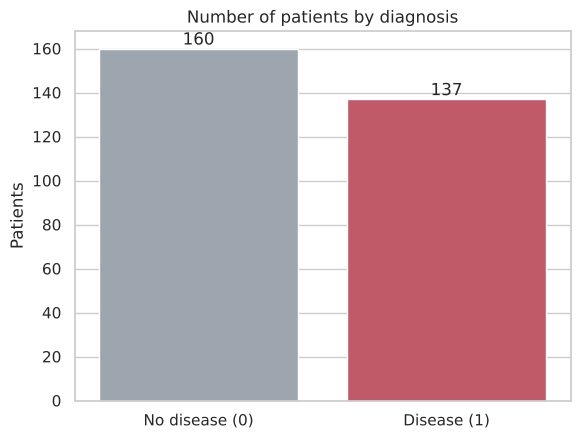

In [8]:
ax = sns.countplot(x="target", hue="target", data=df, palette=["#9aa5b1", "#d1495b"], legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["No disease (0)", "Disease (1)"])
ax.set_title("Number of patients by diagnosis")
ax.set_xlabel(""); ax.set_ylabel("Patients")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

### 4.2 Numeric features compared between the two groups

In [9]:
numeric = ["age", "trestbps", "chol", "thalach", "oldpeak"]
df.groupby("target")[numeric].mean().round(1).rename(index={0: "No disease", 1: "Disease"})

,age,trestbps,chol,thalach,oldpeak
target,,,,,
No disease,52.6,129.2,243.5,158.6,0.6
Disease,56.8,134.6,251.9,139.1,1.6


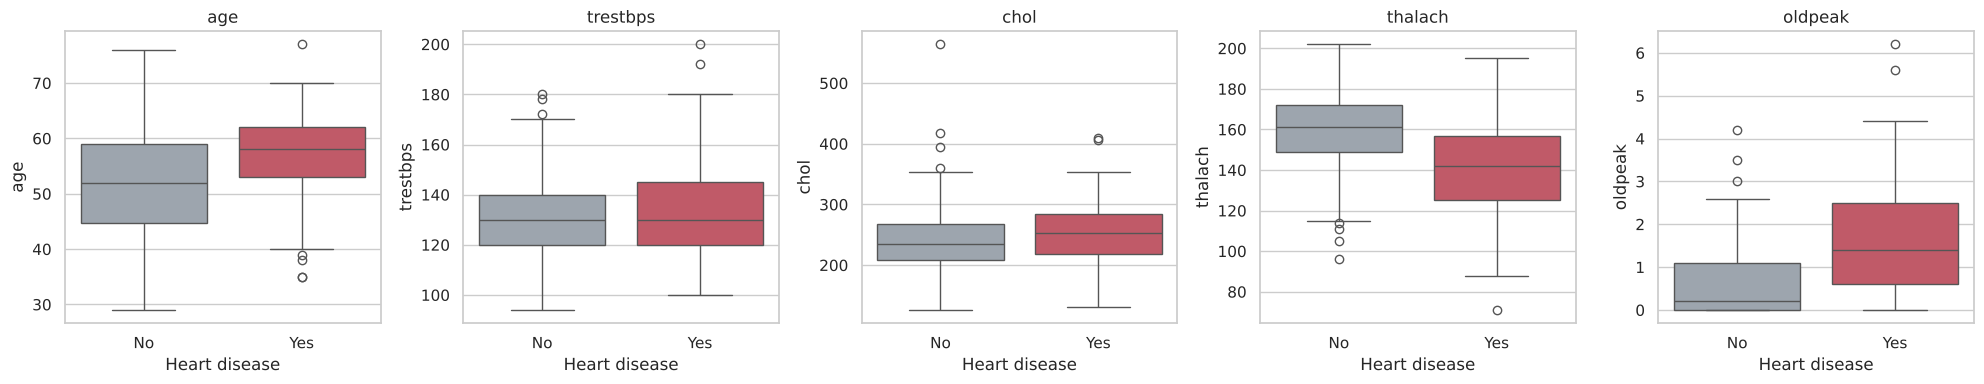

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numeric):
    sns.boxplot(x="target", y=col, hue="target", data=df, ax=ax, palette=["#9aa5b1", "#d1495b"], legend=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No", "Yes"]); ax.set_xlabel("Heart disease")
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Observations**
- Patients with heart disease have a **lower maximum heart rate** (`thalach`) — about 139 vs 158 bpm.
- They have **higher ST depression** (`oldpeak`) — about 1.6 vs 0.6.
- They are slightly **older** (about 56.8 vs 52.6 years).
- Cholesterol and resting blood pressure differ only a little between the groups.

### 4.3 Categorical features: disease rate in each category

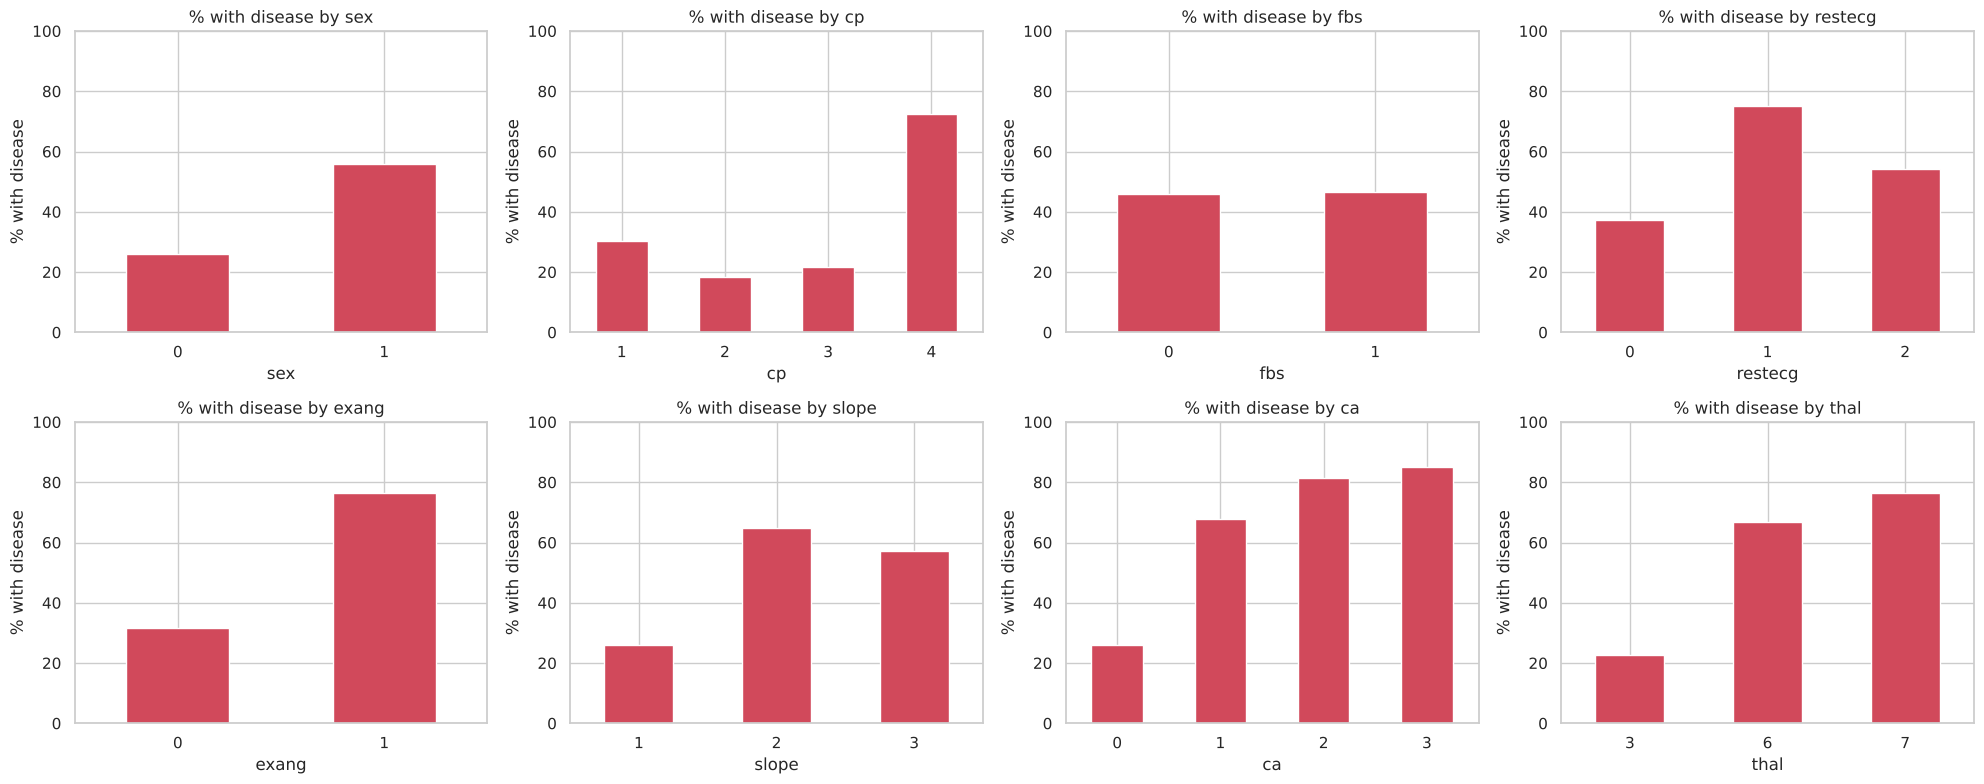

In [11]:
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)["target"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#d1495b")
    ax.set_title(f"% with disease by {col}")
    ax.set_ylabel("% with disease"); ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [12]:
for col in ["sex", "cp", "exang", "ca", "thal"]:
    print(pd.crosstab(df[col], df["target"], normalize="index").mul(100).round(1)
          .rename(columns={0: "% no disease", 1: "% disease"}), "\n")

target  % no disease  % disease
sex                            
0               74.0       26.0
1               44.3       55.7 

target  % no disease  % disease
cp                             
1               69.6       30.4
2               81.6       18.4
3               78.3       21.7
4               27.5       72.5 

target  % no disease  % disease
exang                          
0               68.5       31.5
1               23.7       76.3 

target  % no disease  % disease
ca                             
0               74.1       25.9
1               32.3       67.7
2               18.4       81.6
3               15.0       85.0 

target  % no disease  % disease
thal                           
3               77.4       22.6
6               33.3       66.7
7               23.5       76.5 



**Observations**
- **Sex:** about 55% of men have heart disease vs about 26% of women.
- **Chest pain type 4 (asymptomatic)** has by far the highest disease rate (about 73%). Surprisingly, patients *without* typical chest pain are the most likely to have disease.
- **Exercise-induced angina (`exang` = 1):** about 77% have disease vs about 31% without it.
- **Number of vessels (`ca`):** disease rate rises sharply from about 26% (0 vessels) to 85%+ (3 vessels).
- **Thal = 7 (reversible defect):** about 76% have disease vs about 22% for normal results.

### 4.4 Correlation heatmap

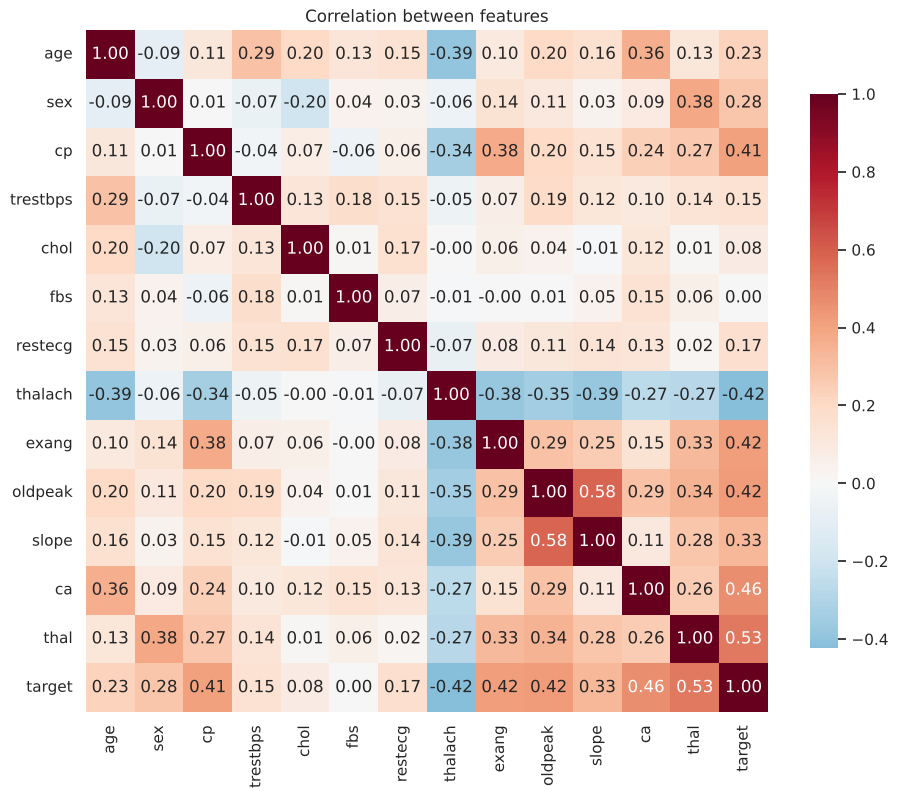

thal        0.53
ca          0.46
oldpeak     0.42
thalach    -0.42
exang       0.42
cp          0.41
slope       0.33
sex         0.28
age         0.23
restecg     0.17
trestbps    0.15
chol        0.08
fbs         0.00
Name: target, dtype: float64


In [13]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation between features")
plt.show()

print(df.corr()["target"].drop("target").sort_values(key=abs, ascending=False).round(2))

The features most strongly linked with `target` are `thal`, `ca`, `oldpeak`, `thalach` (negative), `exang` and `cp`.
No two predictors are so highly correlated with each other that they would cause serious problems for the model.

## 5. Prepare the features

- **Categorical columns with more than two levels** (`cp`, `restecg`, `slope`, `thal`) are **one-hot encoded**, because their numbers are labels, not amounts (chest pain type 4 is not "twice" type 2). `drop_first=True` avoids redundant columns.
- `ca` (0–3 vessels) is a genuine count, so it is kept as a number.
- **Numeric features are standardised** (mean 0, standard deviation 1) so that their coefficients can be compared fairly and the solver converges easily.
- The data is split **80% training / 20% testing**, stratified so both sets keep the same disease ratio.

In [14]:
X = pd.get_dummies(df.drop(columns="target"),
                   columns=["cp", "restecg", "slope", "thal"], drop_first=True, dtype=int)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scale_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])   # fit on training data only
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("Training set:", X_train.shape, " Test set:", X_test.shape)
print("Features:", list(X.columns))

Training set: (237, 18)  Test set: (60, 18)
Features: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'cp_2', 'cp_3', 'cp_4', 'restecg_1', 'restecg_2', 'slope_2', 'slope_3', 'thal_6', 'thal_7']


## 6. Logistic regression

Logistic regression estimates the **probability** that a patient has heart disease:

$$P(\text{disease}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

If this probability is 0.5 or higher, the patient is classified as *disease*; otherwise *no disease*.

In [15]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

## 7. Model evaluation

In [16]:
train_acc = accuracy_score(y_train, model.predict(X_train))
metrics = {
    "Training accuracy": train_acc,
    "Test accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall (sensitivity)": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "ROC AUC": roc_auc_score(y_test, y_prob),
}
pd.Series(metrics).round(3).to_frame("Score")

,Score
Training accuracy,0.869
Test accuracy,0.867
Precision,0.885
Recall (sensitivity),0.821
F1-score,0.852
ROC AUC,0.950


In [17]:
print(classification_report(y_test, y_pred, target_names=['No disease', 'Disease']))

              precision    recall  f1-score   support

  No disease       0.85      0.91      0.88        32
     Disease       0.88      0.82      0.85        28

    accuracy                           0.87        60
   macro avg       0.87      0.86      0.87        60
weighted avg       0.87      0.87      0.87        60



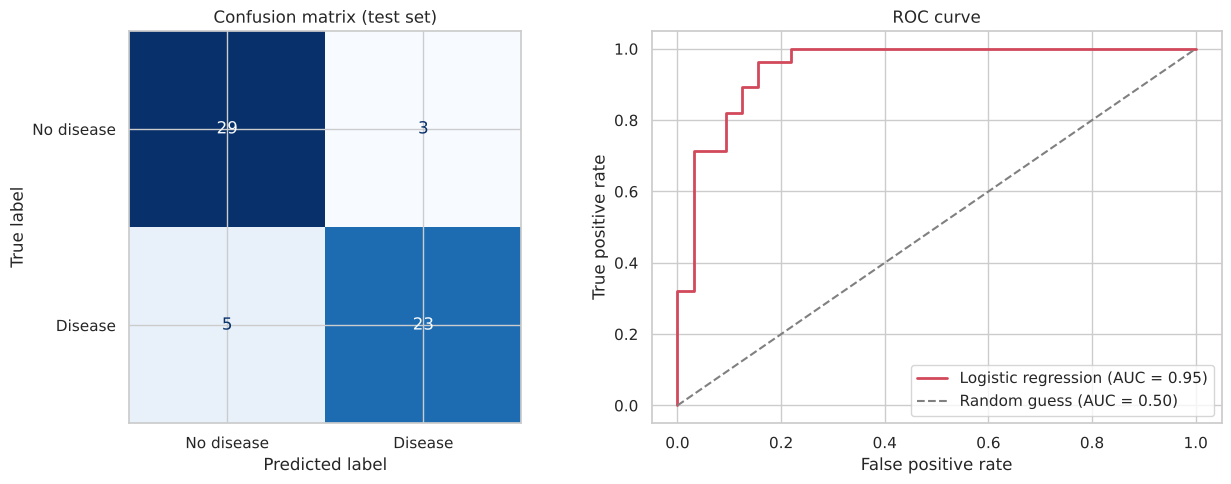

True negatives: 29  False positives: 3  False negatives: 5  True positives: 23


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No disease", "Disease"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (test set)")

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color="#d1495b", lw=2, label=f"Logistic regression (AUC = {roc_auc_score(y_test, y_prob):.2f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Random guess (AUC = 0.50)")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"True negatives: {tn}  False positives: {fp}  False negatives: {fn}  True positives: {tp}")

### 7.1 Cross-validation

A single 80/20 split depends on which patients happen to land in the test set.
**5-fold cross-validation** trains and tests the model five times on different splits and averages the result, giving a more reliable estimate.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

pre = ColumnTransformer([("scale", StandardScaler(), scale_cols)], remainder="passthrough")
pipe = make_pipeline(pre, LogisticRegression(max_iter=1000, random_state=42))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_acc = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
print("Accuracy per fold:", cv_acc.round(3))
print(f"Mean accuracy: {cv_acc.mean():.3f} (± {cv_acc.std():.3f})")
print(f"Mean ROC AUC:  {cv_auc.mean():.3f} (± {cv_auc.std():.3f})")

Accuracy per fold: [0.9   0.833 0.746 0.814 0.831]
Mean accuracy: 0.825 (± 0.049)
Mean ROC AUC:  0.902 (± 0.041)


## 8. Interpreting the coefficients

Each coefficient shows how a feature changes the **log-odds** of heart disease.
Taking `exp(coefficient)` gives the **odds ratio**:

- Odds ratio **> 1** → the feature *increases* the odds of disease
- Odds ratio **< 1** → the feature *decreases* the odds of disease

For scaled numeric features, the odds ratio is the effect of a **one standard deviation** increase.
For 0/1 features, it is the effect of having that characteristic compared with the reference group.

In [20]:
coef = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0]),
}).sort_values("coefficient", key=abs, ascending=False).reset_index(drop=True)
coef.round(3)

,feature,coefficient,odds_ratio
0,thal_7,1.413,4.107
1,cp_4,1.262,3.532
2,sex,0.960,2.612
3,ca,0.860,2.363
4,slope_2,0.777,2.174
5,exang,0.500,1.649
6,oldpeak,0.494,1.639
7,restecg_2,0.488,1.629
8,cp_3,-0.483,0.617
9,slope_3,0.469,1.598


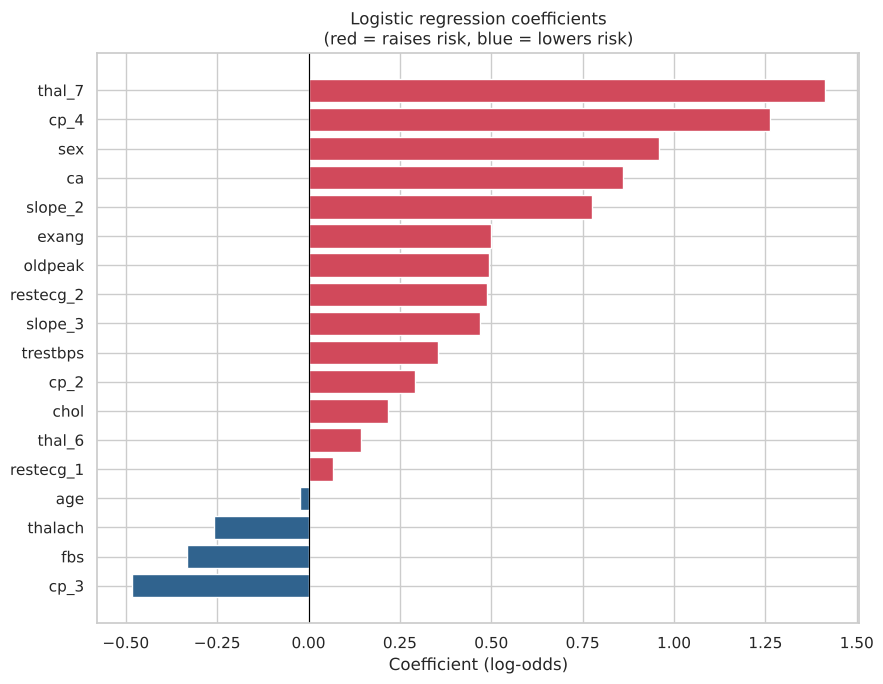

In [21]:
plot_df = coef.sort_values("coefficient")
colors = ["#d1495b" if c > 0 else "#30638e" for c in plot_df["coefficient"]]
plt.figure(figsize=(9, 7))
plt.barh(plot_df["feature"], plot_df["coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic regression coefficients\n(red = raises risk, blue = lowers risk)")
plt.xlabel("Coefficient (log-odds)")
plt.tight_layout(); plt.show()

## 9. Conclusion

- After removing 6 incomplete rows, the dataset contains **297 patients**, of whom about **46% have heart disease**.
- EDA shows that disease is strongly associated with **more blocked vessels (`ca`)**, **a reversible thal defect**, **asymptomatic chest pain**, **exercise-induced angina**, **higher ST depression** and a **lower maximum heart rate**.
- The logistic regression model correctly classifies **86.7% of test patients** (52 of 60), with a **ROC AUC of 0.95**. Five-fold cross-validation gives a mean accuracy of **82.5%** (AUC 0.90), which is a more realistic estimate of performance on new patients.
- The strongest predictors in the model are a reversible thal defect (`thal_7`, odds ratio ≈ 4.1), asymptomatic chest pain (`cp_4`, ≈ 3.5), being male (≈ 2.6) and the number of blocked vessels (`ca`, ≈ 2.4 per standard deviation).
- Training accuracy (86.9%) is almost the same as test accuracy (86.7%), so the model is **not overfitting**.

**Limitations:** the dataset is small (297 patients) and comes from a single hospital, the target was simplified to yes/no,
and logistic regression assumes each feature affects the log-odds in a straight-line way. The model should be seen as a learning
exercise, not a diagnostic tool.